# Laboratory Work #8
## Topic: Plotting Data
## Group: IT2-2404SE
## Full Name: Daniil Kalts

---

### Exercise 1 – Histogram and Stacked Bar Chart (Monthly Temperatures)
Average high (**maximum**) and low (**minimum**) temperatures for each month, in °C:

| Month | Max | Min |
|---|---|---|
| January | 0.7 | -8.4 |
| February | 2.2 | -6.9 |
| March | 8.7 | -1.1 |
| April | 17.3 | 5.9 |
| May | 22.4 | 11.0 |
| June | 27.5 | 15.8 |
| July | 30.0 | 18.0 |
| August | 29.4 | 16.9 |
| September | 24.2 | 11.5 |
| October | 16.3 | 4.6 |
| November | 8.2 | -1.3 |
| December | 2.3 | -6.4 |

**Tasks:**
- a. Create a DataFrame **temps** indexed by month with the columns `'Max'` and `'Min'`.
- b. Show the data as a **histogram**.
- c. Show the data as a **stacked bar chart** by month.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

temps = pd.DataFrame({
    'Max': [0.7, 2.2, 8.7, 17.3, 22.4, 27.5, 30.0, 29.4, 24.2, 16.3, 8.2, 2.3],
    'Min': [-8.4, -6.9, -1.1, 5.9, 11.0, 15.8, 18.0, 16.9, 11.5, 4.6, -1.3, -6.4]
}, index=months)

print(temps)

      Max   Min
Jan   0.7  -8.4
Feb   2.2  -6.9
Mar   8.7  -1.1
Apr  17.3   5.9
May  22.4  11.0
Jun  27.5  15.8
Jul  30.0  18.0
Aug  29.4  16.9
Sep  24.2  11.5
Oct  16.3   4.6
Nov   8.2  -1.3
Dec   2.3  -6.4


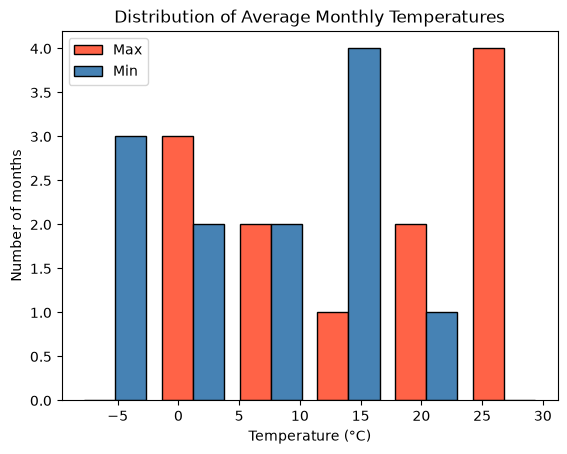

In [2]:
plt.hist([temps['Max'], temps['Min']], bins=6, color=['tomato', 'steelblue'],
         edgecolor='black', label=['Max', 'Min'])
plt.title('Distribution of Average Monthly Temperatures')
plt.xlabel('Temperature (°C)')
plt.ylabel('Number of months')
plt.legend()
plt.show()

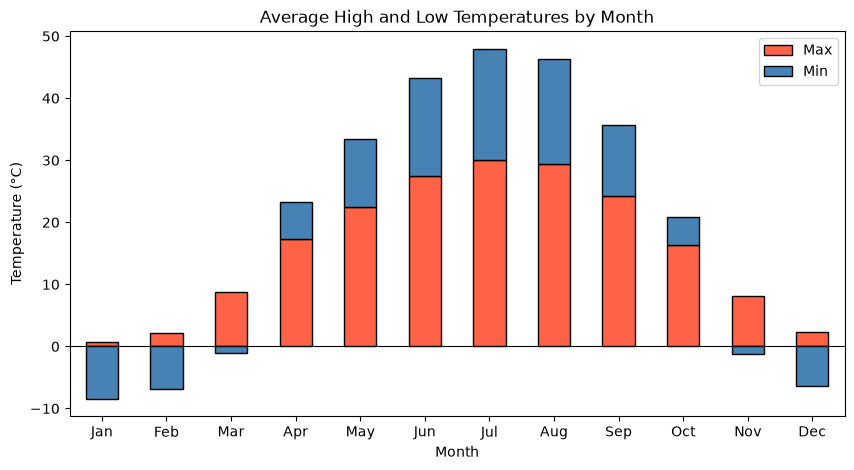

In [3]:
temps.plot(kind='bar', stacked=True, color=['tomato', 'steelblue'],
           edgecolor='black', figsize=(10, 5))
plt.title('Average High and Low Temperatures by Month')
plt.xlabel('Month')
plt.ylabel('Temperature (°C)')
plt.axhline(0, color='black', linewidth=0.8)
plt.xticks(rotation=0)
plt.show()

**Note:** pandas stacks positive and negative values separately, so in the winter months the negative minimum goes below zero and the maximum goes above it.

### Exercise 2 – Customized Pie Charts (Regions of Kazakhstan)
Data source: [Regions of Kazakhstan](https://en.wikipedia.org/wiki/Regions_of_Kazakhstan) – area (km²) and population (2022) of each region and city of republican significance.

**Tasks:**
- a. Create a DataFrame **regions** indexed by entity with the columns `'Area'` and `'Population'`.
- b. Show **Area** as a customized pie chart using pandas `plot()`.
- c. Show **Population** as a customized pie chart using matplotlib `pie()`.

In [4]:
regions = pd.DataFrame({
    'Area': [185500, 146219, 300629, 682, 105100, 797, 118631, 57, 97700, 144264, 118500,
             239100, 196001, 226019, 165642, 97993, 124800, 1163, 116100, 151339, 188900],
    'Population': [610183, 786012, 924845, 2147113, 1497025, 1340782, 689674, 34544, 730818, 1215482, 698952,
                   1134146, 832445, 830901, 761401, 534966, 754829, 1184113, 2110502, 686655, 221014]
}, index=['Abai', 'Aqmola', 'Aqtobe', 'Almaty (city)', 'Almaty Region', 'Astana', 'Atyrau', 'Baikonur',
          'East Kazakhstan', 'Jambyl', 'Jetisu', 'Karaganda', 'Kostanay', 'Kyzylorda', 'Mangystau',
          'North Kazakhstan', 'Pavlodar', 'Shymkent', 'Turkistan', 'West Kazakhstan', 'Ulytau'])

print(regions)

                    Area  Population
Abai              185500      610183
Aqmola            146219      786012
Aqtobe            300629      924845
Almaty (city)        682     2147113
Almaty Region     105100     1497025
Astana               797     1340782
Atyrau            118631      689674
Baikonur              57       34544
East Kazakhstan    97700      730818
Jambyl            144264     1215482
Jetisu            118500      698952
Karaganda         239100     1134146
Kostanay          196001      832445
Kyzylorda         226019      830901
Mangystau         165642      761401
North Kazakhstan   97993      534966
Pavlodar          124800      754829
Shymkent            1163     1184113
Turkistan         116100     2110502
West Kazakhstan   151339      686655
Ulytau            188900      221014


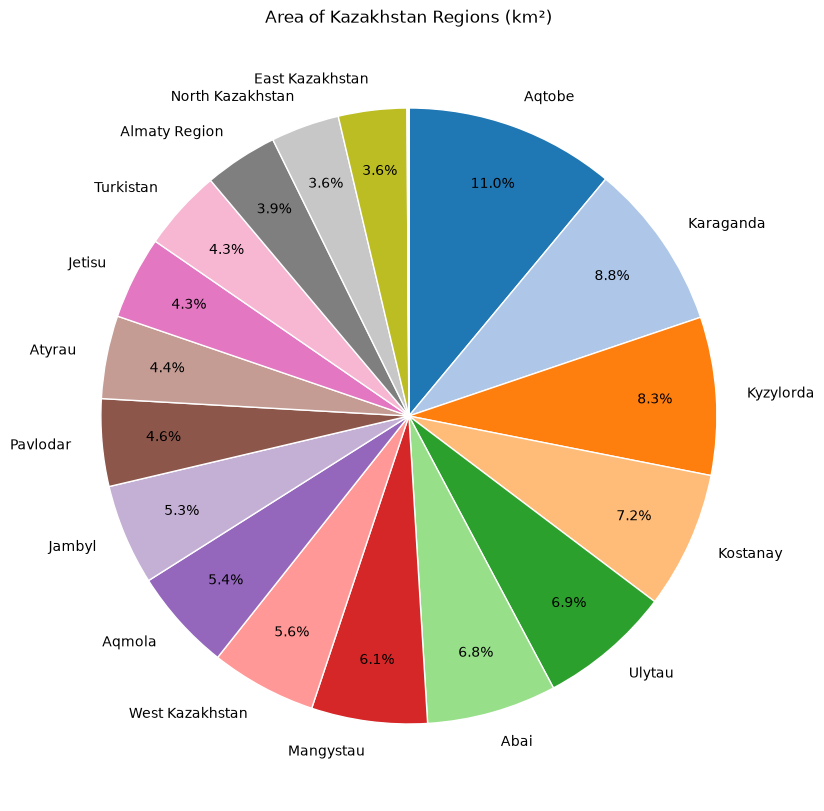

In [5]:
area = regions['Area'].sort_values(ascending=False).to_frame()
area_labels = [name if share >= 0.01 else '' for name, share in (area['Area'] / area['Area'].sum()).items()]

area.plot(kind='pie', y='Area', labels=area_labels, figsize=(10, 10), legend=False,
          autopct=lambda p: f'{p:.1f}%' if p >= 2 else '',
          pctdistance=0.8, startangle=90, counterclock=False,
          colormap='tab20', wedgeprops={'edgecolor': 'white', 'linewidth': 1})
plt.title('Area of Kazakhstan Regions (km²)')
plt.ylabel('')
plt.show()

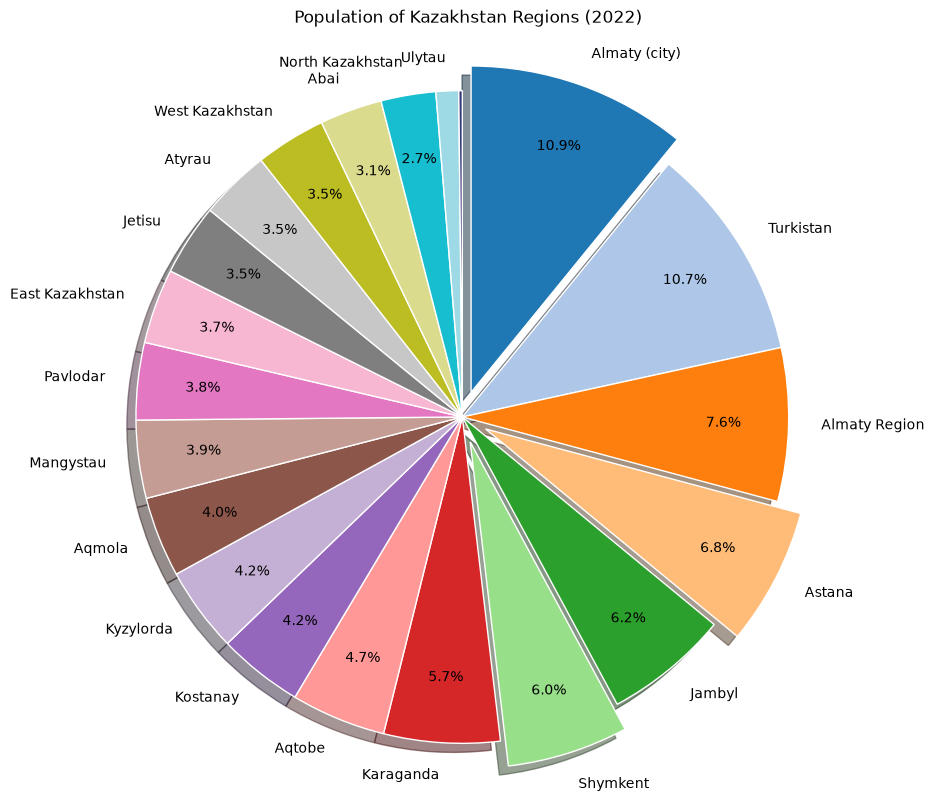

In [6]:
population = regions['Population'].sort_values(ascending=False)
population_labels = [name if share >= 0.01 else '' for name, share in (population / population.sum()).items()]
explode = [0.08 if name in ('Almaty (city)', 'Astana', 'Shymkent') else 0 for name in population.index]

fig, ax = plt.subplots(figsize=(10, 10))
ax.pie(population, labels=population_labels, explode=explode,
       autopct=lambda p: f'{p:.1f}%' if p >= 2 else '',
       pctdistance=0.8, shadow=True, startangle=90, counterclock=False,
       colors=plt.cm.tab20.colors + plt.cm.tab20b.colors[:1],
       wedgeprops={'edgecolor': 'white', 'linewidth': 1})
ax.axis('equal')
ax.set_title('Population of Kazakhstan Regions (2022)')
plt.show()

**Note:** slices smaller than 1% are left unlabeled so their names don't overlap: Almaty (city), Astana, Shymkent and Baikonur on the area pie, and Baikonur on the population pie. Percentages are shown only for slices of 2% or more.

The cities of republican significance (Almaty, Astana, Shymkent) are pulled out of the population pie. They hold a large share of the population (about 24% together) but almost no area (under 0.1% each).